<a href="https://colab.research.google.com/github/baynobu/PCVK-Ganjil-26/blob/main/P10_01_Abdul_Rahman_Hanif_D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **D1. Praktikum Deteksi Obyek Dasar**

---

| Keterangan | Detail |
|---|---|
| **Nama** | Abdul Rahman Hanif Darmawan |
| **NIM** | 244107020232 |
| **Kelas** | TI-3G |
| **Absen** | 01 |

---

### **1. Import Library, dan Mount Google Drive**

In [ ]:
# Import library yang dibutuhkan
import cv2 as cv
import cv2
import numpy as np
from matplotlib import pyplot as plt
import os
import random
import pickle

# Akses Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Definisi path direktori utama pada Google Drive
BASE_PATH = '/content/drive/MyDrive/Uni/Internal/Semester 5/PCdVK/'

# Path spesifik subfolder
folder_objdet = os.path.join(BASE_PATH, 'Images Object Detection/')
folder_facedet = os.path.join(BASE_PATH, 'facedet/')
folder_haarcascades = os.path.join(BASE_PATH, 'haarcascades/')
folder_ktm = os.path.join(BASE_PATH, 'KTM/')

def get_path(filename, primary_folder=None):
    """Helper function fleksibel untuk menemukan path file dengan fallback."""
    if primary_folder and os.path.exists(os.path.join(primary_folder, filename)):
        return os.path.join(primary_folder, filename)
    root_file = os.path.join(BASE_PATH, filename)
    if os.path.exists(root_file):
        return root_file
    for f in [folder_objdet, folder_facedet, folder_haarcascades, folder_ktm]:
        cand = os.path.join(f, filename)
        if os.path.exists(cand):
            return cand
    return os.path.join(primary_folder if primary_folder else BASE_PATH, filename)

print("Inisialisasi library dan path berhasil.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Inisialisasi library dan path berhasil.


### **2. Implementasi 6 Metode Template Matching pada OpenCV**

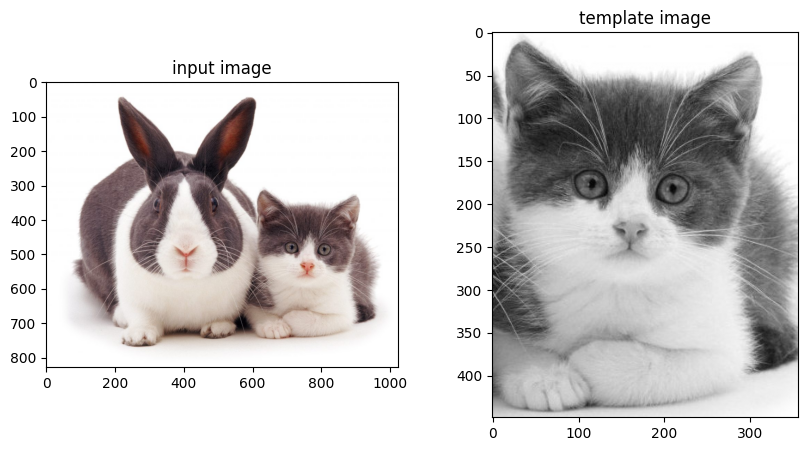

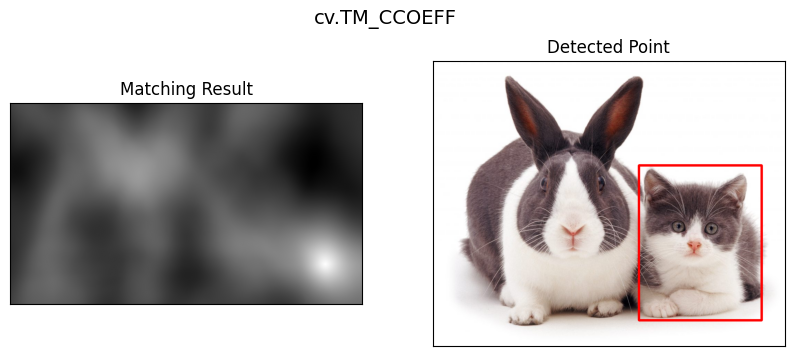

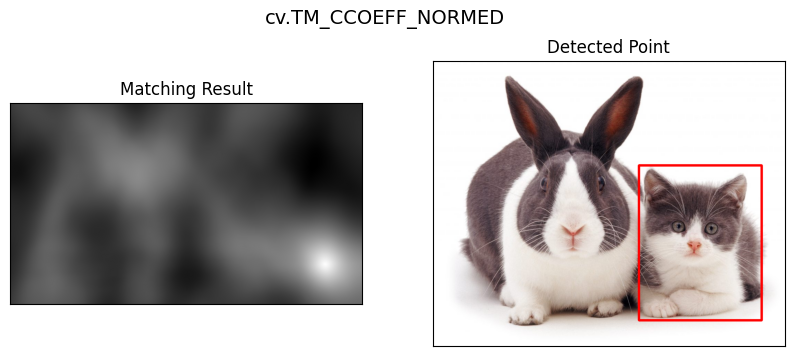

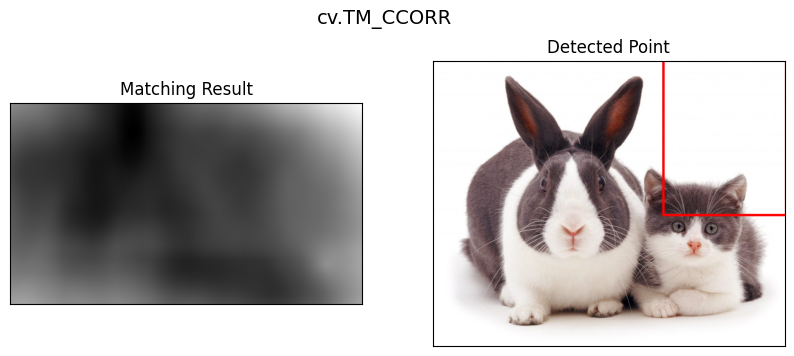

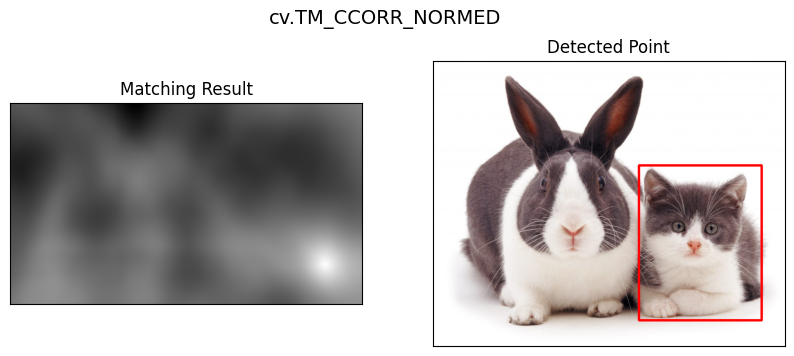

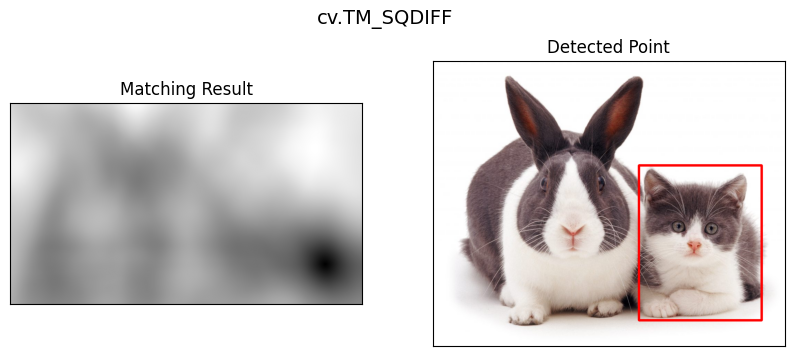

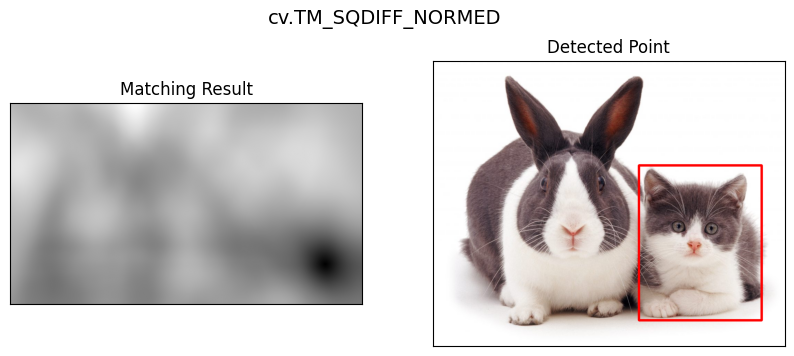

In [ ]:
# Membaca citra input dan citra template
img_path = get_path('cats_and_bunnies.jpg', folder_objdet)
tpl_path = get_path('cat2_template.jpg', folder_objdet)
if not os.path.exists(tpl_path):
    tpl_path = get_path('cat2_templatejpg.jpg', folder_objdet)

img_bgr = cv.imread(img_path)
img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)
img_gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)

template = cv.imread(tpl_path, 0)
w, h = template.shape[::-1]

# Menampilkan Input Image dan Template Image berdampingan
plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img_rgb)
plt.title('input image')
plt.subplot(122), plt.imshow(template, cmap='gray')
plt.title('template image')
plt.show()

# Daftar 6 metode Template Matching di OpenCV
methods = ['cv.TM_CCOEFF', 'cv.TM_CCOEFF_NORMED', 'cv.TM_CCORR',
           'cv.TM_CCORR_NORMED', 'cv.TM_SQDIFF', 'cv.TM_SQDIFF_NORMED']

# Melakukan perulangan untuk menerapkan keenam metode
for meth in methods:
    img_display = img_rgb.copy()
    method = eval(meth)

    # Menerapkan template matching pada citra grayscale
    res = cv.matchTemplate(img_gray, template, method)
    min_val, max_val, min_loc, max_loc = cv.minMaxLoc(res)

    # Jika metodenya TM_SQDIFF atau TM_SQDIFF_NORMED, ambil nilai minimum
    if method in [cv.TM_SQDIFF, cv.TM_SQDIFF_NORMED]:
        top_left = min_loc
    else:
        top_left = max_loc

    bottom_right = (top_left[0] + w, top_left[1] + h)

    # Menggambar kotak pembatas warna merah tebal (thickness=5)
    cv.rectangle(img_display, top_left, bottom_right, (255, 0, 0), 5)

    # Menampilkan hasil Matching Result dan Detected Point tanpa ticks
    plt.figure(figsize=(10, 4))

    plt.subplot(121)
    plt.imshow(res, cmap='gray')
    plt.title('Matching Result')
    plt.xticks([]), plt.yticks([])

    plt.subplot(122)
    plt.imshow(img_display)
    plt.title('Detected Point')
    plt.xticks([]), plt.yticks([])

    plt.suptitle(meth, fontsize=14)
    plt.show()

### **3. Implementasi Template Matching Tanpa Library OpenCV untuk Multiple Object**

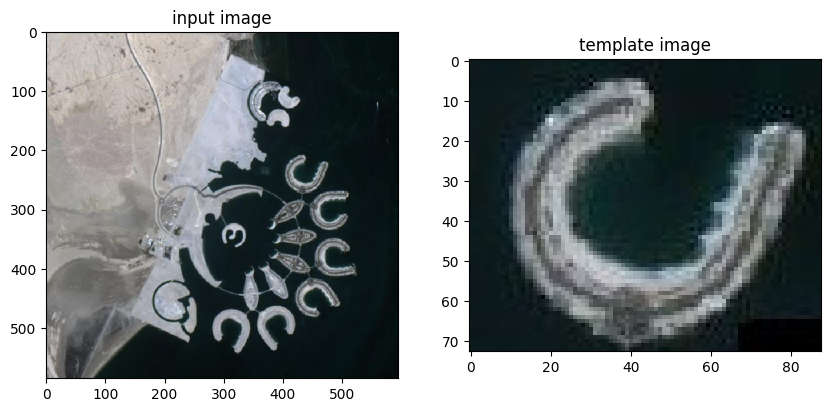

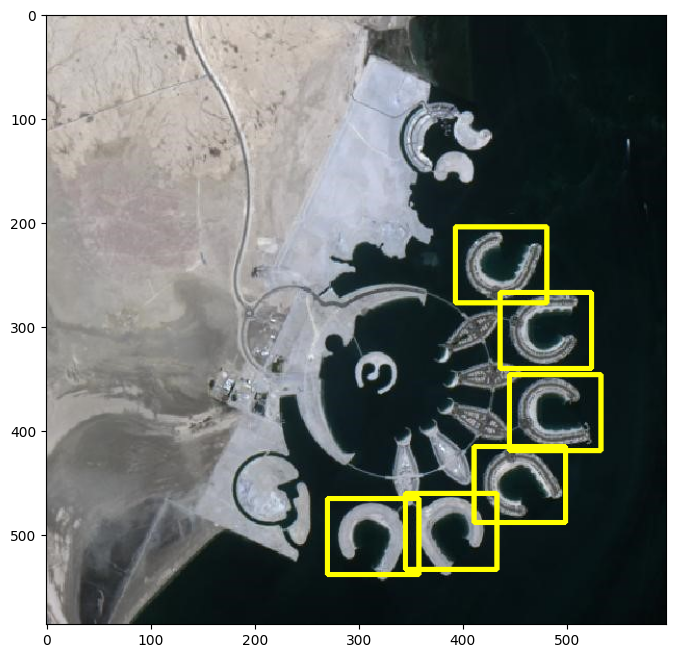

In [ ]:
# Membaca dan menyiapkan citra input serta citra template
img_path = get_path('bahrain.jpg', folder_objdet)
tpl_path = get_path('bahrain-template.jpg', folder_objdet)

img_rgb = cv.cvtColor(cv.imread(img_path), cv.COLOR_BGR2RGB)
temp_rgb = cv.cvtColor(cv.imread(tpl_path), cv.COLOR_BGR2RGB)

img_gray = cv.cvtColor(img_rgb, cv.COLOR_BGR2GRAY).astype(float)
temp_gray = cv.cvtColor(temp_rgb, cv.COLOR_BGR2GRAY).astype(float)

# Menampilkan citra input dan citra template
plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img_rgb), plt.title('input image')
plt.subplot(122), plt.imshow(temp_rgb), plt.title('template image')
plt.show()

# Perhitungan manual Template Matching (Normalized Cross-Correlation)
H, W = img_gray.shape
h, w = temp_gray.shape
R = np.zeros((H - h + 1, W - w + 1))

temp_diff = temp_gray - np.mean(temp_gray)
temp_norm = np.linalg.norm(temp_diff)

for y in range(H - h + 1):
    for x in range(W - w + 1):
        patch_diff = img_gray[y:y+h, x:x+w] - np.mean(img_gray[y:y+h, x:x+w])
        patch_norm = np.linalg.norm(patch_diff)

        if patch_norm > 0:
            R[y, x] = np.sum(temp_diff * patch_diff) / (temp_norm * patch_norm)

# Menyeleksi 6 koordinat terbaik menggunakan Non-Maximum Suppression (NMS)
R[:180, :] = -1  # Abaikan area daratan atas
R[:, :250] = -1  # Abaikan area daratan kiri

img_result = img_rgb.copy()
nms_h, nms_w = int(h * 0.65), int(w * 0.65)

for _ in range(6):
    y_max, x_max = np.unravel_index(np.argmax(R), R.shape)

    # Menggambar kotak pembatas warna kuning pada titik terpilih
    cv.rectangle(img_result, (x_max, y_max), (x_max + w, y_max + h), (255, 255, 0), 3)

    # Menghapus nilai di sekitar titik terpilih agar objek yang sama tidak terdeteksi ulang
    R[max(0, y_max - nms_h):min(R.shape[0], y_max + nms_h),
      max(0, x_max - nms_w):min(R.shape[1], x_max + nms_w)] = -1

# Menampilkan hasil akhir deteksi objek
plt.figure(figsize=(8, 8))
plt.imshow(img_result)
plt.show()

### **4. Implementasi Metode Edge Detection (Sobel, Canny, dan Laplacian)**

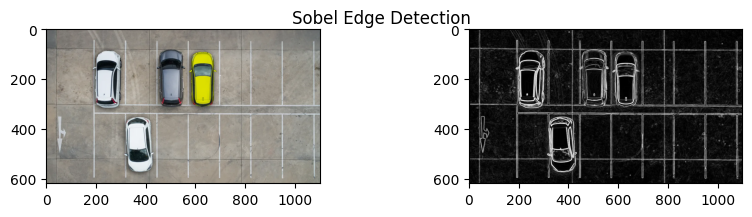

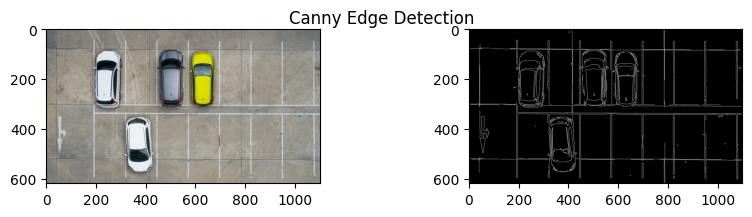

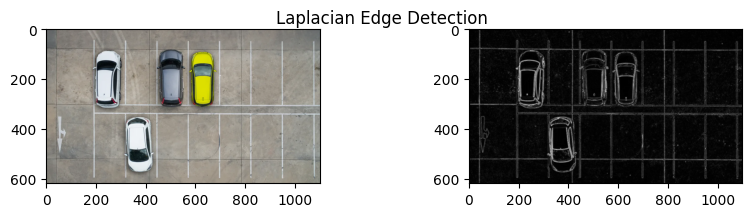

In [ ]:
car_park_path = get_path('car-park.jpg', folder_objdet)
img_bgr = cv.imread(car_park_path)
img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)
img_gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)

img_blur = cv.GaussianBlur(img_gray, (3, 3), 0)

# Sobel Edge Detection
sobel_x = cv.Sobel(img_blur, cv.CV_64F, 1, 0, ksize=3)
sobel_y = cv.Sobel(img_blur, cv.CV_64F, 0, 1, ksize=3)
sobel_combined = cv.magnitude(sobel_x, sobel_y)
sobel_edges = cv.convertScaleAbs(sobel_combined)

plt.figure(figsize=(10, 2))
plt.suptitle('Sobel Edge Detection')
plt.subplot(121), plt.imshow(img_rgb)
plt.subplot(122), plt.imshow(sobel_edges, cmap='gray')
plt.show()

# Canny Edge Detection
canny_edges = cv.Canny(img_blur, 100, 200)

plt.figure(figsize=(10, 2))
plt.suptitle('Canny Edge Detection')
plt.subplot(121), plt.imshow(img_rgb)
plt.subplot(122), plt.imshow(canny_edges, cmap='gray')
plt.show()

# Laplacian Edge Detection
laplacian = cv.Laplacian(img_blur, cv.CV_64F, ksize=3)
laplacian_edges = cv.convertScaleAbs(laplacian)

plt.figure(figsize=(10, 2))
plt.suptitle('Laplacian Edge Detection')
plt.subplot(121), plt.imshow(img_rgb)
plt.subplot(122), plt.imshow(laplacian_edges, cmap='gray')
plt.show()

### **5. Implementasi Metode Corner Detection (Harris dan Shi-Tomasi)**

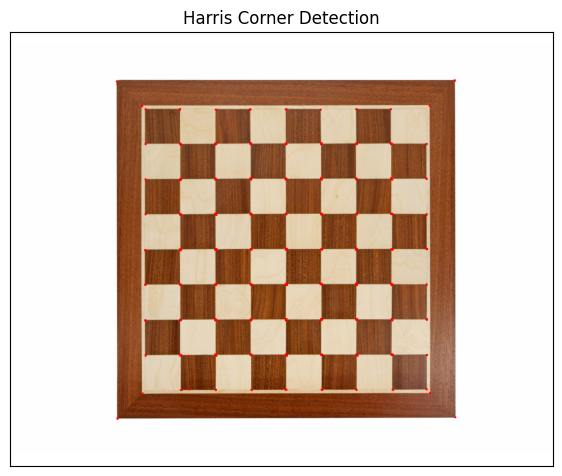

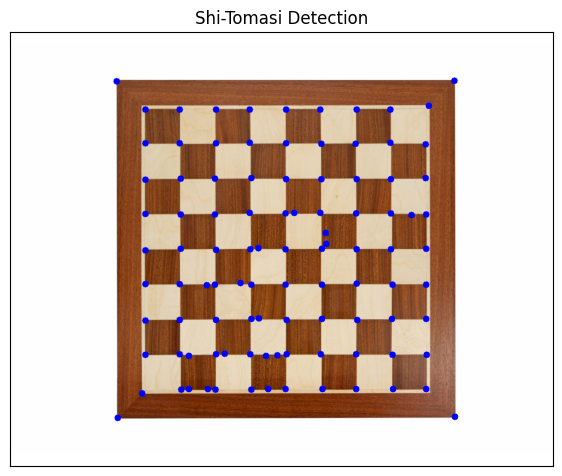

In [ ]:
chess_path = get_path('chess-board.jpg', folder_objdet)
img_bgr = cv.imread(chess_path)
img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)
img_gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)

# Harris Corner Detection
img_harris = img_rgb.copy()
gray_float = np.float32(img_gray)

dst = cv.cornerHarris(gray_float, 2, 3, 0.04)

# Dilasi hasil corner agar titik sudut merah terlihat lebih jelas
dst = cv.dilate(dst, None)

# Menandai sudut yang melebihi threshold
img_harris[dst > 0.01 * dst.max()] = [255, 0, 0]

plt.figure(figsize=(7, 7))
plt.title('Harris Corner Detection')
plt.imshow(img_harris)
plt.xticks([]), plt.yticks([])
plt.show()

# Shi-Tomasi Detection
img_shitomasi = img_rgb.copy()

corners = cv.goodFeaturesToTrack(img_gray, 100, 0.01, 10)
# Kompatibel dengan NumPy 2.x
corners = np.int32(corners)

# Menggambar titik lingkaran biru pada setiap sudut yang ditemukan
for i in corners:
    x, y = i.ravel()
    cv.circle(img_shitomasi, (int(x), int(y)), 6, (0, 0, 255), -1)

plt.figure(figsize=(7, 7))
plt.title('Shi-Tomasi Detection')
plt.imshow(img_shitomasi)
plt.xticks([]), plt.yticks([])
plt.show()

### **6. Implementasi Grid Detection dengan Metode Hough Transform**

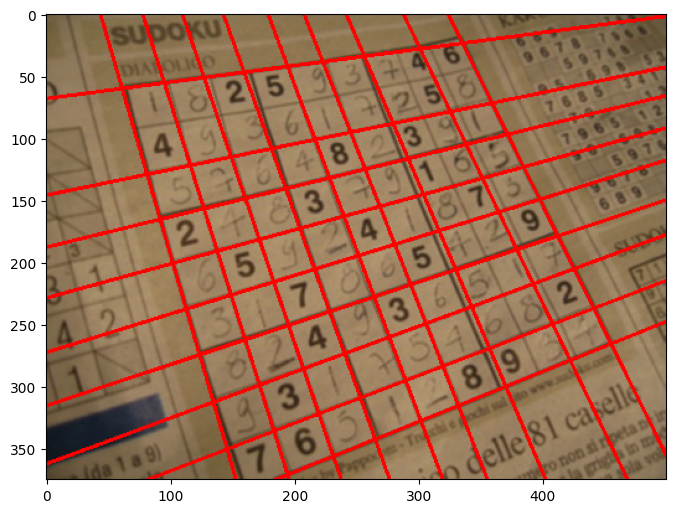

In [ ]:
sudoku_path = get_path('sudoku.jpg', folder_objdet)
img_bgr = cv.imread(sudoku_path)
img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)
img_gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)

img_blur = cv.GaussianBlur(img_gray, (5, 5), 0)

# Canny Edge Detection
edges = cv.Canny(img_blur, 50, 150, apertureSize=3)

# HoughLines
lines = cv.HoughLines(edges, 1, np.pi / 180, 110)

# Filter garis duplikat (Grouping & Merging sesuai teori modul langkah 5)
def filter_lines(lines, rho_thresh=20, theta_thresh=np.deg2rad(8)):
    if lines is None:
        return []
    lines = [l[0] for l in lines]
    groups = []
    for rho, theta in lines:
        placed = False
        for g in groups:
            g_rho, g_theta = np.mean(g, axis=0)
            if abs(rho - g_rho) < rho_thresh and abs(theta - g_theta) < theta_thresh:
                g.append((rho, theta))
                placed = True
                break
        if not placed:
            groups.append([(rho, theta)])
    return [tuple(np.mean(g, axis=0)) for g in groups]

filtered = filter_lines(lines)

# Menggambar garis merah hasil Hough Transform pada citra
img_hough = img_rgb.copy()
for rho, theta in filtered:
    a = np.cos(theta)
    b = np.sin(theta)
    x0 = a * rho
    y0 = b * rho
    x1 = int(x0 + 1000 * (-b))
    y1 = int(y0 + 1000 * (a))
    x2 = int(x0 - 1000 * (-b))
    y2 = int(y0 - 1000 * (a))
    cv.line(img_hough, (x1, y1), (x2, y2), (255, 0, 0), 2)

# Menampilkan hasil gambar
plt.figure(figsize=(8, 8))
plt.imshow(img_hough)
plt.show()

### **7. Implementasi Contour Detection**

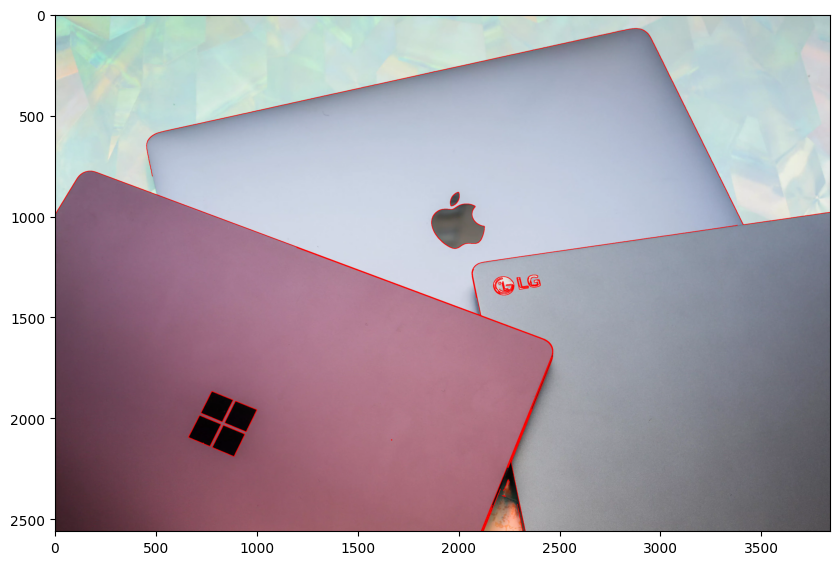

In [ ]:
laptop_path = get_path('laptop.jpg', folder_objdet)
img_bgr = cv.imread(laptop_path)
img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)
img_gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)

# Mengubah citra menjadi citra biner menggunakan Canny Edge Detection
img_blur = cv.GaussianBlur(img_gray, (5, 5), 0)
edges = cv.Canny(img_blur, 50, 150)

# Menemukan kontur menggunakan cv.findContours()
contours, hierarchy = cv.findContours(edges, cv.RETR_TREE, cv.CHAIN_APPROX_SIMPLE)

# Menggambarkan kontur dengan warna merah (thickness=2)
img_contour = img_rgb.copy()
cv.drawContours(img_contour, contours, -1, (255, 0, 0), 2)

# Menampilkan hasil akhir Contour Detection
plt.figure(figsize=(10, 10))
plt.imshow(img_contour)
plt.show()

# **D2. Praktikum Feature Matching dan Face Detection**

### **8. Face Detection Menggunakan Haar Cascades**

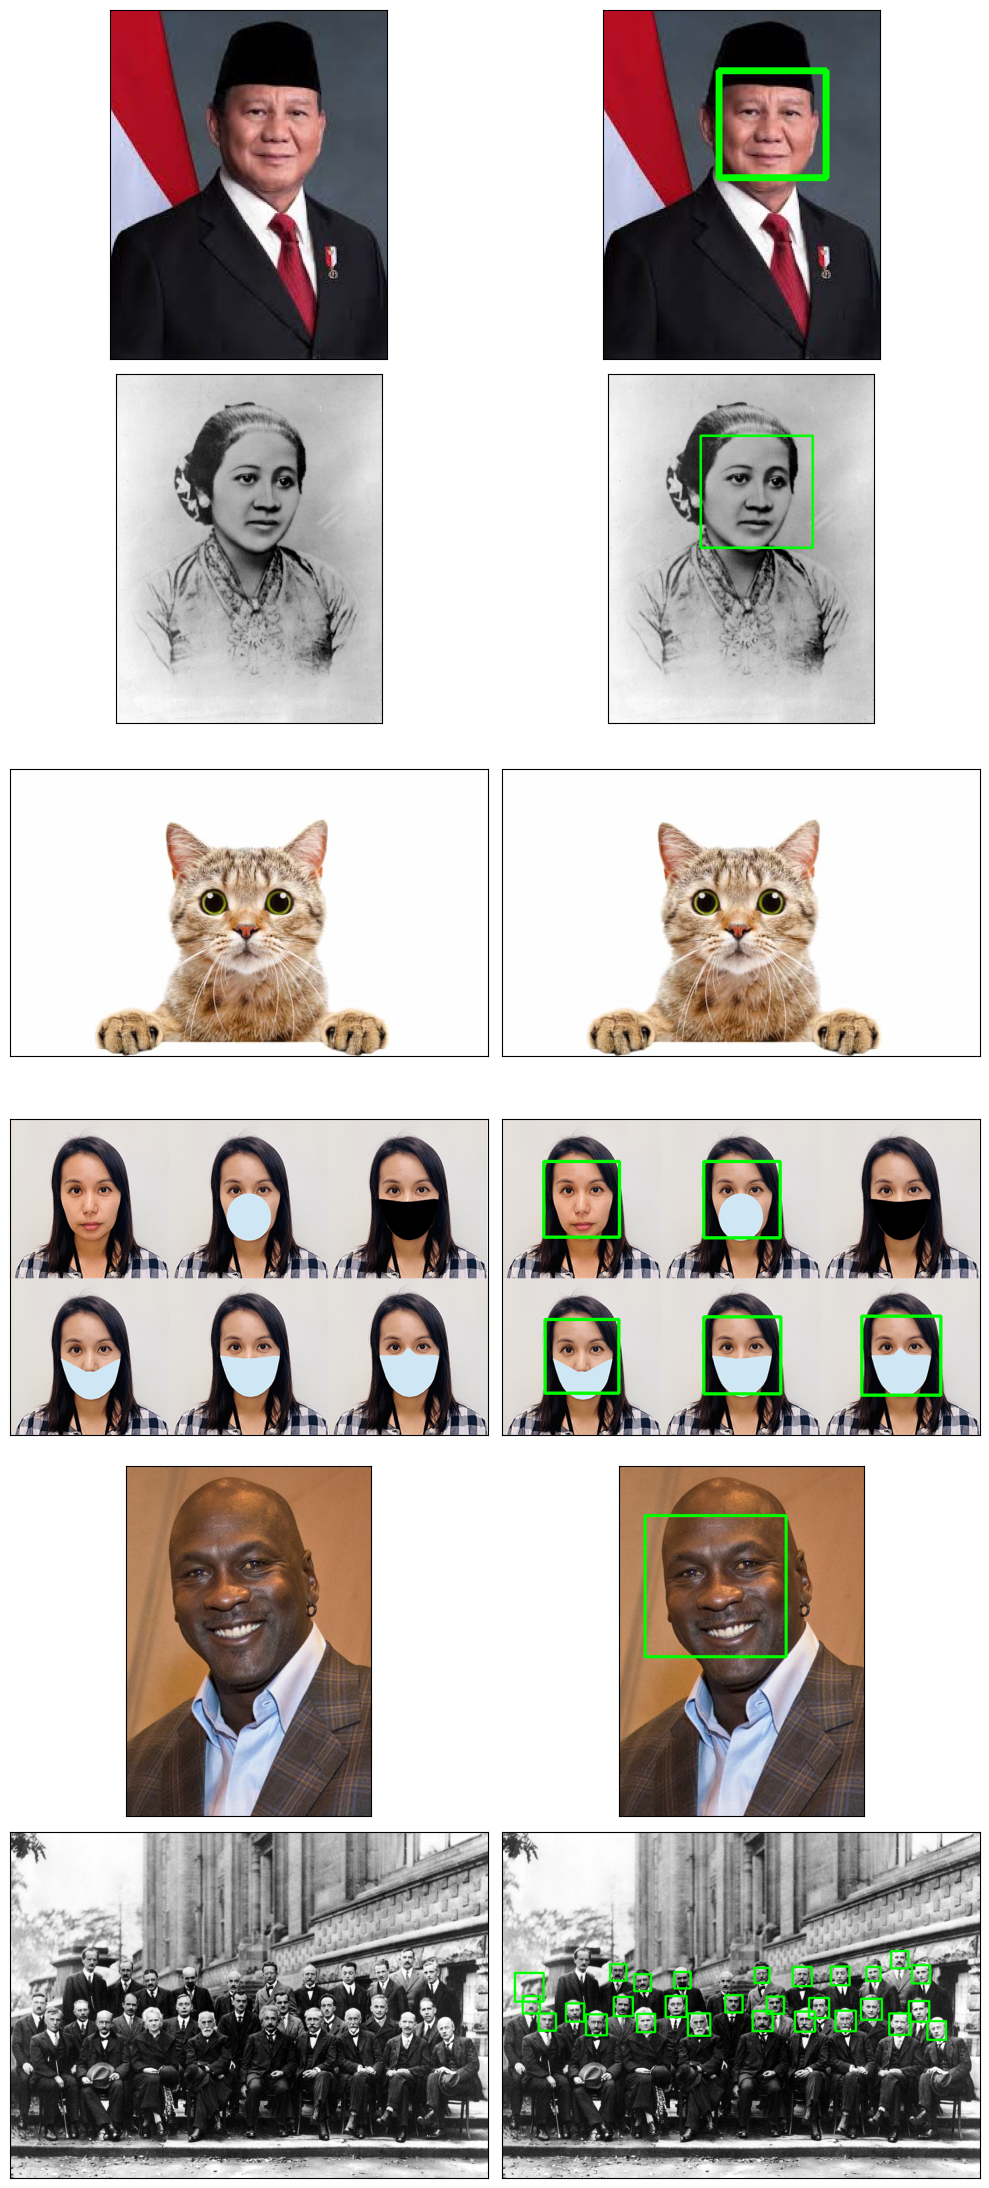

In [ ]:
# Memuat model pretrained Haar Cascade untuk wajah
haar_face_path = get_path('haarcascade_frontalface_alt.xml', folder_haarcascades)
cascade_wajah = cv.CascadeClassifier(haar_face_path)

daftar_gambar = [
    'prabowo.jpg',
    'kartini.jpg',
    'kucing.jpg',
    'mask.png',
    'mjordan.jpg',
    'solvayconf.jpg'
]

plt.figure(figsize=(10, 22))

for i, nama_file in enumerate(daftar_gambar):
    img_path = get_path(nama_file, folder_facedet)
    img_bgr = cv.imread(img_path)
    if img_bgr is None:
        continue

    img_gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)

    # Mendeteksi koordinat wilayah wajah
    roi_wajah = cascade_wajah.detectMultiScale(img_gray)

    # Menggambar kotak hijau di sekeliling wajah yang terdeteksi
    img_result = img_bgr.copy()
    for (x, y, w, h) in roi_wajah:
        cv.rectangle(img_result, (x, y), (x + w, y + h), (0, 255, 0), 3)

    # Konversi BGR ke RGB untuk ditampilkan di matplotlib
    img_asli_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)
    img_result_rgb = cv.cvtColor(img_result, cv.COLOR_BGR2RGB)

    # Citra Asli
    plt.subplot(len(daftar_gambar), 2, 2 * i + 1)
    plt.imshow(img_asli_rgb)
    plt.xticks([]), plt.yticks([])

    # Hasil Face Detection
    plt.subplot(len(daftar_gambar), 2, 2 * i + 2)
    plt.imshow(img_result_rgb)
    plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

### **9. Face Detection pada Wajah Kucing**

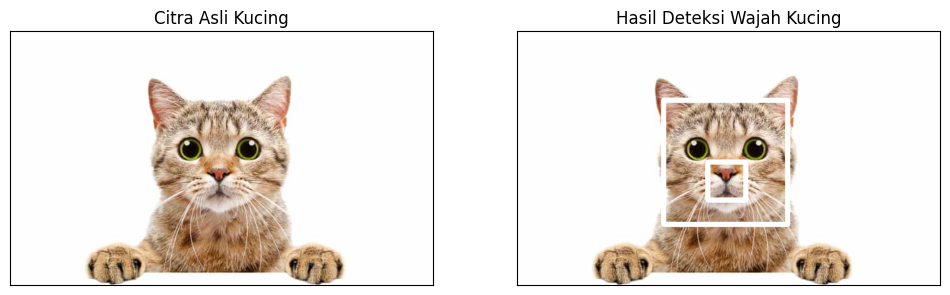

In [ ]:
# Memuat model pretrained Haar Cascade khusus wajah kucing
haar_cat_path = get_path('haarcascade_frontalcatface.xml', folder_haarcascades)
cascade_kucing = cv.CascadeClassifier(haar_cat_path)

kucing_path = get_path('kucing.jpg', folder_facedet)
img_bgr = cv.imread(kucing_path)
img_gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)

# Mendeteksi koordinat wilayah wajah kucing
roi_kucing = cascade_kucing.detectMultiScale(img_gray, scaleFactor=1.1, minNeighbors=3)

# Menggambar kotak berwarna putih tebal di sekeliling wajah kucing
img_result = img_bgr.copy()
for (x, y, w, h) in roi_kucing:
    cv.rectangle(img_result, (x, y), (x + w, y + h), (255, 255, 255), 10)

img_asli_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)
img_result_rgb = cv.cvtColor(img_result, cv.COLOR_BGR2RGB)

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(img_asli_rgb)
plt.title('Citra Asli Kucing')
plt.xticks([]), plt.yticks([])

plt.subplot(1, 2, 2)
plt.imshow(img_result_rgb)
plt.title('Hasil Deteksi Wajah Kucing')
plt.xticks([]), plt.yticks([])

plt.show()

### **10. Eyes Detection pada Wajah Pak Prabowo**

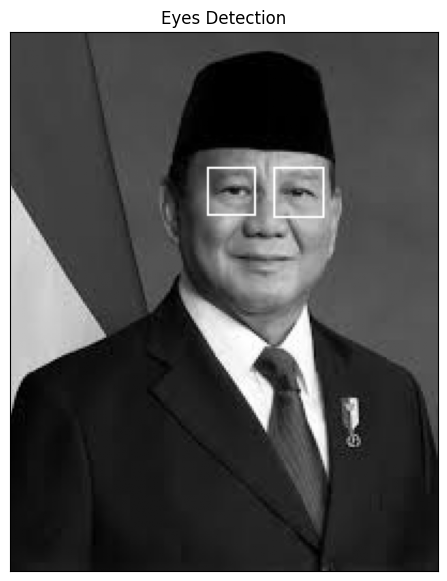

In [ ]:
# Memuat model pretrained Haar Cascade untuk wajah dan mata
cascade_wajah = cv.CascadeClassifier(get_path('haarcascade_frontalface_alt.xml', folder_haarcascades))
cascade_mata = cv.CascadeClassifier(get_path('haarcascade_eye.xml', folder_haarcascades))

prabowo_path = get_path('prabowo.jpg', folder_facedet)
img_bgr = cv.imread(prabowo_path)
img_gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)

# Mendeteksi wilayah wajah
roi_wajah = cascade_wajah.detectMultiScale(img_gray, scaleFactor=1.1, minNeighbors=5)

img_result = img_bgr.copy()

# Mendeteksi mata di dalam area wajah
for (x, y, w, h) in roi_wajah:
    roi_gray = img_gray[y:y+h, x:x+w]
    roi_color = img_result[y:y+h, x:x+w]

    mata = cascade_mata.detectMultiScale(roi_gray, scaleFactor=1.1, minNeighbors=1)
    for (ex, ey, ew, eh) in mata:
        cv.rectangle(roi_color, (ex, ey), (ex + ew, ey + eh), (255, 255, 255), 1)

img_result_gray = cv.cvtColor(img_result, cv.COLOR_BGR2GRAY)

plt.figure(figsize=(7, 7))
plt.imshow(img_result_gray, cmap='gray')
plt.title('Eyes Detection')
plt.xticks([]), plt.yticks([])
plt.show()

### **11. Deteksi Senyuman pada Gambar People**

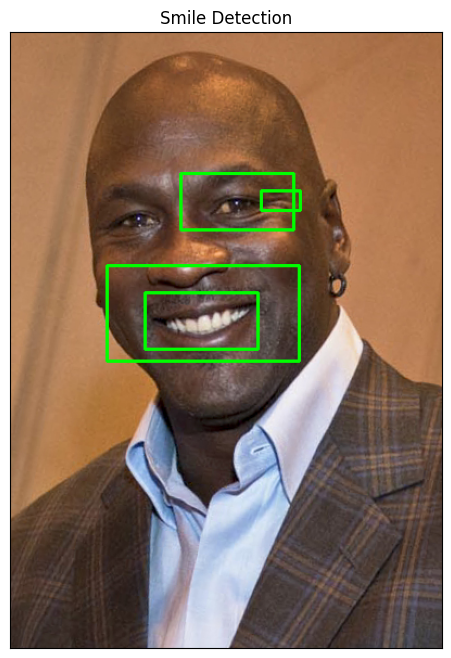

In [ ]:
# Memuat model pretrained Haar Cascade untuk wajah dan senyuman
cascade_wajah = cv.CascadeClassifier(get_path('haarcascade_frontalface_alt.xml', folder_haarcascades))
cascade_senyum = cv.CascadeClassifier(get_path('haarcascade_smile.xml', folder_haarcascades))

people_path = get_path('people.png', folder_facedet)
if not os.path.exists(people_path):
    people_path = get_path('people.jpg', folder_facedet)

# Jika belum tersedia di Google Drive, gunakan citra senyuman yang ada
if not os.path.exists(people_path):
    people_path = get_path('mjordan.jpg', folder_facedet)

img_bgr = cv.imread(people_path)
img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)
img_gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)

# Mendeteksi wajah terlebih dahulu agar pencarian senyuman fokus di area wajah
wajah = cascade_wajah.detectMultiScale(img_gray, scaleFactor=1.1, minNeighbors=3)

img_result = img_rgb.copy()

for (x, y, w, h) in wajah:
    roi_gray = img_gray[y:y+h, x:x+w]
    roi_color = img_result[y:y+h, x:x+w]

    # Mendeteksi senyuman di dalam area wajah
    senyum = cascade_senyum.detectMultiScale(roi_gray, scaleFactor=1.7, minNeighbors=5)

    for (sx, sy, sw, sh) in senyum:
        cv.rectangle(roi_color, (sx, sy), (sx + sw, sy + sh), (0, 255, 0), 2)

plt.figure(figsize=(12, 8))
plt.imshow(img_result)
plt.title('Smile Detection')
plt.xticks([]), plt.yticks([])
plt.show()

### **12. Face Tracking**

In [ ]:
from IPython.display import display, Javascript, Image
from google.colab.output import eval_js
from base64 import b64decode, b64encode
import cv2
import numpy as np
import PIL
import io
import html
import time

#### Helper Functions

In [ ]:
# function to convert the JavaScript object into an OpenCV image
def js_to_image(js_reply):
  """
  Params:
          js_reply: JavaScript object containing image from webcam
  Returns:
          img: OpenCV BGR image
  """
  # decode base64 image
  image_bytes = b64decode(js_reply.split(',')[1])
  # convert bytes to numpy array
  jpg_as_np = np.frombuffer(image_bytes, dtype=np.uint8)
  # decode numpy array into OpenCV BGR image
  img = cv2.imdecode(jpg_as_np, flags=1)

  return img

# function to convert OpenCV Rectangle bounding box image into base64 byte string to be overlayed on video stream
def bbox_to_bytes(bbox_array):
  """
  Params:
          bbox_array: Numpy array (pixels) containing rectangle to overlay on video stream.
  Returns:
        bytes: Base64 image byte string
  """
  # convert array into PIL image
  bbox_PIL = PIL.Image.fromarray(bbox_array)
  io_buf = io.BytesIO()
  # format was changed to png
  bbox_PIL.save(io_buf, format='png')
  # format response payload
  bbox_bytes = 'data:image/png;base64,{}'.format((str(b64encode(io_buf.getvalue()), 'utf-8')))

  return bbox_bytes

#### Haar Cascade Classifier

In [ ]:
# initialize the Haar Cascade face detection model
haar_path = get_path('haarcascade_frontalface_default.xml', folder_haarcascades)
if not os.path.exists(haar_path):
    haar_path = get_path('haarcascade_frontalface_alt.xml', folder_haarcascades)
face_cascade = cv2.CascadeClassifier(haar_path)

#### Webcam Images

In [ ]:
def take_photo(filename='photo.jpg', quality=0.8):
  js = Javascript('''
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const capture = document.createElement('button');
      capture.textContent = 'Capture';
      div.appendChild(capture);

      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});

      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();

      // Resize the output to fit the video element.
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

      // Wait for Capture to be clicked.
      await new Promise((resolve) => capture.onclick = resolve);

      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }
    ''')
  display(js)

  # get photo data
  data = eval_js('takePhoto({})'.format(quality))
  # get OpenCV format image
  img = js_to_image(data)
  # grayscale image for face detection
  gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
  print(gray.shape)
  # get face coordinates
  faces = face_cascade.detectMultiScale(gray)
  # get face bounding box for overlay
  for (x,y,w,h) in faces:
      img = cv2.rectangle(img,(x,y),(x+w,y+h),(255,0,0),2)
  # save image
  cv2.imwrite(filename, img)

  return filename

<IPython.core.display.Javascript object>

(480, 640)
Saved to photo.jpg


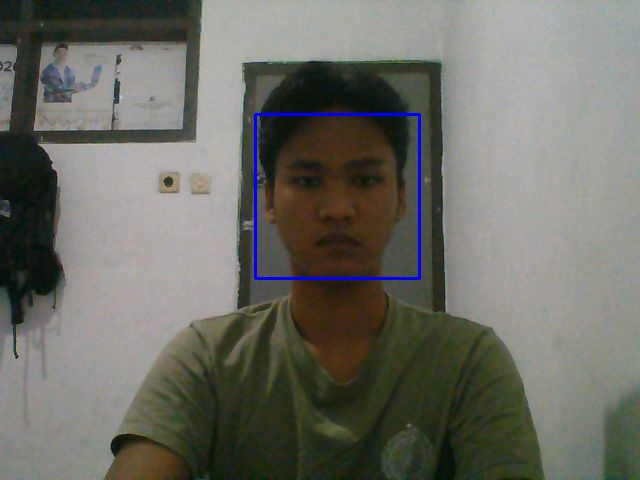

In [ ]:
try:
  filename = take_photo('photo.jpg')
  print('Saved to {}'.format(filename))

  # Show the image which was just taken.
  display(Image(filename))
except Exception as err:
  # Errors will be thrown if the user does not have a webcam or if they do not
  # grant the page permission to access it.
  print(str(err))

#### Webcam Videos

In [ ]:
# JavaScript to properly create our live video stream using our webcam as input
def video_stream():
  js = Javascript('''
    var video;
    var div = null;
    var stream;
    var captureCanvas;
    var imgElement;
    var labelElement;

    var pendingResolve = null;
    var shutdown = false;

    function removeDom() {
       stream.getVideoTracks()[0].stop();
       video.remove();
       div.remove();
       video = null;
       div = null;
       stream = null;
       imgElement = null;
       captureCanvas = null;
       labelElement = null;
    }

    function onAnimationFrame() {
      if (!shutdown) {
        window.requestAnimationFrame(onAnimationFrame);
      }
      if (pendingResolve) {
        var result = "";
        if (!shutdown) {
          captureCanvas.getContext('2d').drawImage(video, 0, 0, 640, 480);
          result = captureCanvas.toDataURL('image/jpeg', 0.8)
        }
        var resolve = pendingResolve;
        pendingResolve = null;
        resolve(result);
      }
    }

    async function createDom() {
      if (div !== null) {
        return stream;
      }

      div = document.createElement('div');
      div.style.border = '2px solid black';
      div.style.padding = '4px';
      div.style.width = 'max-content';
      div.style.maxHeight = 'max-content';

      layout = document.createElement('div');
      layout.style.display = 'flex';
      layout.style.flexDirection = 'row';

      video = document.createElement('video');
      video.style.display = 'block';
      video.style.width = '640px';
      video.style.height = '480px';
      video.setAttribute('playsinline', '');

      stream = await navigator.mediaDevices.getUserMedia({video: {facingMode: "user"}});
      video.srcObject = stream;
      await video.play();

      layout.appendChild(video);

      captureCanvas = document.createElement('canvas');
      captureCanvas.width = 640;
      captureCanvas.height = 480;

      imgElement = document.createElement('img');
      imgElement.style.position = 'absolute';
      imgElement.style.zIndex = '1';
      imgElement.style.width = '640px';
      imgElement.style.height = '480px';
      layout.appendChild(imgElement);

      labelElement = document.createElement('div');
      labelElement.innerText = 'Initializing...';
      div.appendChild(labelElement);
      div.appendChild(layout);

      document.body.appendChild(div);

      window.requestAnimationFrame(onAnimationFrame);

      return stream;
    }
    async function stream_frame(label, imgData) {
      if (shutdown) {
        removeDom();
        shutdown = false;
        return '';
      }

      var preCreate = Date.now();
      stream = await createDom();

      var preWait = Date.now();
      if (labelElement) {
        labelElement.innerText = label;
      }

      if (imgData != "") {
        var videoRect = video.getClientRects()[0];
        imgElement.style.top = videoRect.top + "px";
        imgElement.style.left = videoRect.left + "px";
        imgElement.style.width = videoRect.width + "px";
        imgElement.style.height = videoRect.height + "px";
        imgElement.src = imgData;
      }

      var preResolve = Date.now();
      return new Promise(function(resolve, reject) {
        pendingResolve = resolve;
      });
    }
    function shutdown_stream() {
      shutdown = true;
    }
    ''')
  display(js)

def video_frame(label, bbox):
  data = eval_js('stream_frame("{}", "{}")'.format(label, bbox))
  return data

In [ ]:
# start streaming video from webcam
MAX_FRAMES = 100
count = 0

try:
    video_stream()
    # label for video
    label_html = 'Capturing live video... (otomatis berhenti setelah 100 frame atau klik Stop)'
    # initialze bounding box to empty
    bbox = ''
    while count < MAX_FRAMES:
        js_reply = video_frame(label_html, bbox)
        if not js_reply:
            break

        # convert JS response to OpenCV Image
        img = js_to_image(js_reply)

        # create transparent overlay for bounding box
        bbox_array = np.zeros([480, 640, 4], dtype=np.uint8)

        # grayscale image for face detection
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

        # get face region coordinates
        faces = face_cascade.detectMultiScale(gray)
        # get face bounding box for overlay
        for (x, y, w, h) in faces:
            bbox_array = cv2.rectangle(bbox_array, (x, y), (x + w, y + h), (255, 0, 0), 2)

        bbox_array[:, :, 3] = (bbox_array.max(axis=2) > 0).astype(int) * 255
        # convert overlay of bbox into bytes
        bbox_bytes = bbox_to_bytes(bbox_array)
        # update bbox so next frame gets new overlay
        bbox = bbox_bytes
        count += 1

    print(f"\nLive streaming selesai ({count} frame berhasil diproses).")
except (Exception, KeyboardInterrupt):
    print("\nLive video stream dihentikan oleh pengguna.")

<IPython.core.display.Javascript object>


Live video stream dihentikan oleh pengguna.


### **13. Blurring pada Bagian Wajah**

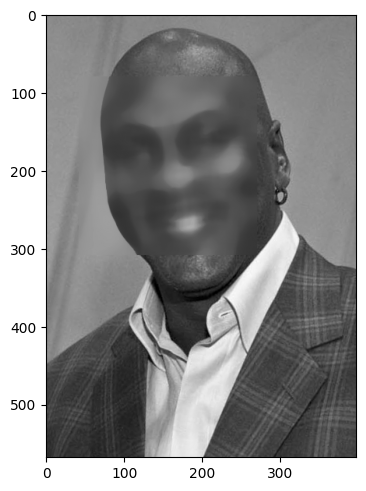

In [ ]:
# Memuat model pretrained Haar Cascade untuk wajah
cascade_wajah = cv.CascadeClassifier(get_path('haarcascade_frontalface_alt.xml', folder_haarcascades))

# Membaca citra dalam format grayscale (0) sesuai modul
img_gray = cv.imread(get_path('mjordan.jpg', folder_facedet), 0)

# Mendeteksi koordinat wilayah wajah
roi_wajah = cascade_wajah.detectMultiScale(img_gray, scaleFactor=1.1, minNeighbors=5)

# Melakukan blurring dengan cv.medianBlur
img_blur = img_gray.copy()
for (x, y, w, h) in roi_wajah:
    potongan_wajah = img_blur[y:y+h, x:x+w]

    # Menerapkan medianBlur dengan kernel 25
    wajah_kabur = cv.medianBlur(potongan_wajah, 25)

    img_blur[y:y+h, x:x+w] = wajah_kabur

plt.figure(figsize=(4, 7))
plt.imshow(img_blur, cmap='gray')
plt.show()

### **14. Mengolah Gambar KTM (Face Cropping & Feature Matching)**

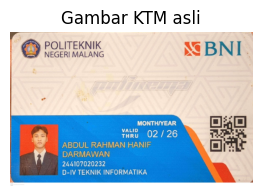

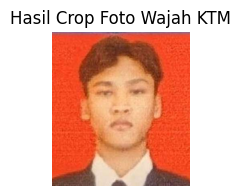

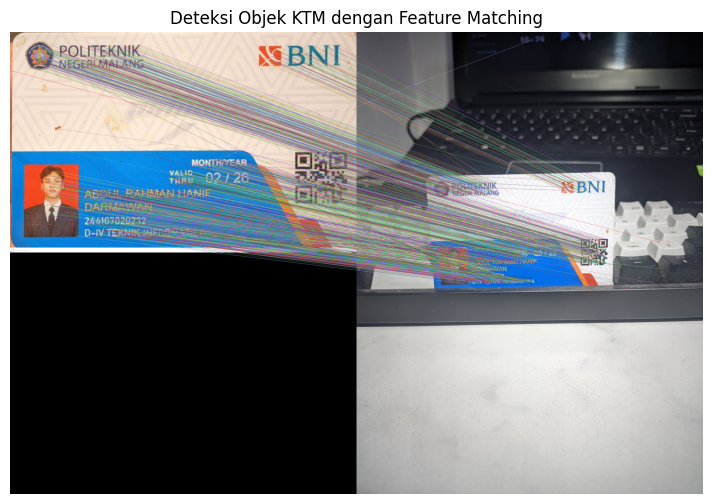

In [ ]:

ktm_path = get_path('KTM1d.jpg')
if not os.path.exists(ktm_path):
    ktm_path = get_path('KTM.jpeg', folder_ktm)

ktm_bgr = cv.imread(ktm_path)
ktm_rgb = cv.cvtColor(ktm_bgr, cv.COLOR_BGR2RGB)
ktm_gray = cv.cvtColor(ktm_bgr, cv.COLOR_BGR2GRAY)

plt.figure(figsize=(4, 2))
plt.imshow(ktm_rgb)
plt.title('Gambar KTM asli')
plt.axis('off')
plt.show()

cascade_wajah = cv.CascadeClassifier(get_path('haarcascade_frontalface_alt.xml', folder_haarcascades))
roi_wajah = cascade_wajah.detectMultiScale(ktm_gray, scaleFactor=1.1, minNeighbors=4)

if len(roi_wajah) > 0:
    x, y, w, h = roi_wajah[0]
    # Memberikan margin (padding) agar area pas foto KTM terpotong rapi
    pad_x = int(w * 0.35)
    pad_y_top = int(h * 0.35)
    pad_y_bottom = int(h * 0.55)

    y1 = max(0, y - pad_y_top)
    y2 = min(ktm_rgb.shape[0], y + h + pad_y_bottom)
    x1 = max(0, x - pad_x)
    x2 = min(ktm_rgb.shape[1], x + w + pad_x)
    foto_ktm = ktm_rgb[y1:y2, x1:x2]
else:
    # Koordinat pas foto default pada KTM1d (Abdul Rahman Hanif Darmawan)
    h_k, w_k, _ = ktm_rgb.shape
    foto_ktm = ktm_rgb[int(0.60 * h_k):int(0.96 * h_k), int(0.03 * w_k):int(0.20 * w_k)]

plt.figure(figsize=(2, 2))
plt.imshow(foto_ktm)
plt.title('Hasil Crop Foto Wajah KTM')
plt.axis('off')
plt.show()
scene_path = get_path('OBJ1.jpg')
ktm_scene_bgr = cv.imread(scene_path)
ktm_scene = cv.cvtColor(ktm_scene_bgr, cv.COLOR_BGR2RGB)

# Inisialisasi SIFT
sift = cv.SIFT_create()
kp1, des1 = sift.detectAndCompute(ktm_rgb, None)
kp2, des2 = sift.detectAndCompute(ktm_scene, None)

# Brute-Force Matcher dengan kNN (k=2)
bf = cv.BFMatcher()
matches = bf.knnMatch(des1, des2, k=2)

# Ratio Test untuk menyaring kecocokan terbaik (Lowe's ratio < 0.75)
good = []
for match1, match2 in matches:
    if match1.distance < 0.75 * match2.distance:
        good.append([match1])

# Menggambar garis penghubung kecocokan fitur SIFT yang bersih
sift_matches = cv.drawMatchesKnn(ktm_rgb, kp1, ktm_scene, kp2, good, None, flags=2)

plt.figure(figsize=(10, 6))
plt.imshow(sift_matches)
plt.title('Deteksi Objek KTM dengan Feature Matching')
plt.axis('off')
plt.show()

# **D3. Tugas Pengayaan**

### **Import Library dan Menentukan Lokasi Dataset**

In [ ]:
import os
import cv2
import random
import pickle
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tqdm.notebook import tqdm
from keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    ZeroPadding2D
)
from keras.models import Model
from keras.optimizers import Adam
from keras.utils import to_categorical

# Lokasi dataset
DATA_TRAINING = os.path.join(BASE_PATH, "dataset/training")
DATA_TESTING  = os.path.join(BASE_PATH, "dataset/testing")

# Pastikan folder dataset lokal/drive tersedia
os.makedirs(DATA_TRAINING, exist_ok=True)
os.makedirs(DATA_TESTING, exist_ok=True)

print("Folder training:", DATA_TRAINING)
print("Folder testing :", DATA_TESTING)

Folder training: /content/drive/MyDrive/Uni/Internal/Semester 5/PCdVK/dataset/training
Folder testing : /content/drive/MyDrive/Uni/Internal/Semester 5/PCdVK/dataset/testing


### **Membuat Data Testing dari KTM**

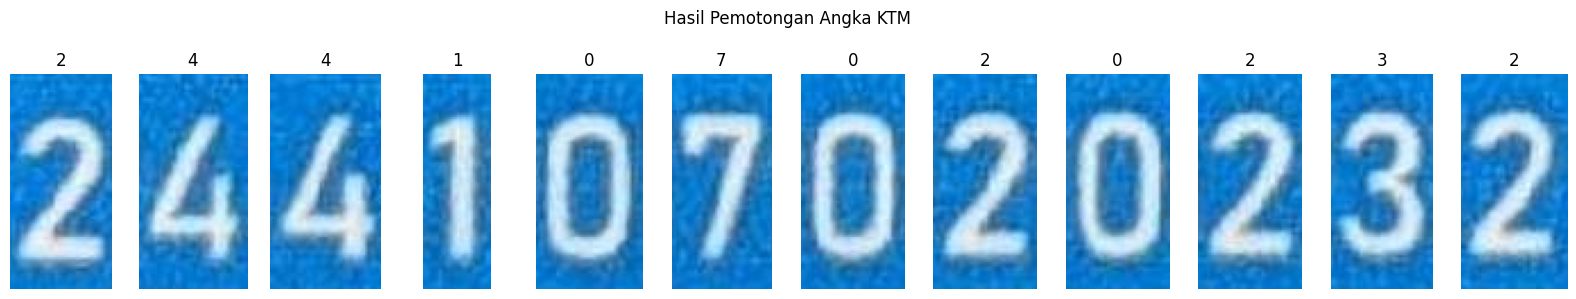

Jumlah karakter: 12
Lokasi penyimpanan: /content/drive/MyDrive/Uni/Internal/Semester 5/PCdVK/dataset/testing/KTM


In [ ]:
# Membaca gambar KTM asli mahasiswa
ktm_source_path = get_path('KTM1d.jpg')
if not os.path.exists(ktm_source_path):
    ktm_source_path = get_path('KTM.jpeg', folder_ktm)

img_ktm = cv2.imread(ktm_source_path)
img_ktm_rgb = cv2.cvtColor(img_ktm, cv2.COLOR_BGR2RGB)
h_ktm, w_ktm, _ = img_ktm.shape

# Nomor NIM Mahasiswa: Abdul Rahman Hanif Darmawan
teks_nomor = "244107020232"

# 1. Potong area teks nomor NIM secara presisi
if h_ktm > 1500:
    # Resolusi tinggi KTM1d.jpg (1909x3000)
    y1_nim, y2_nim = int(0.83 * h_ktm), int(0.88 * h_ktm)
    x1_nim = int(0.21 * w_ktm)
    nim_roi = img_ktm[y1_nim:y2_nim, x1_nim:x1_nim + 600]
    # Ambil batas area spesifik teks NIM (lebar ~545 px)
    nomor_ktm = nim_roi[:, 10:555]
else:
    # Resolusi standar KTM.jpeg (815x1280)
    nomor_ktm = img_ktm[615:660, 440:675]

# 2. Batas koordinat X proporsional untuk setiap angka 2-4-4-1-0-7-0-2-0-2-3-2
w_cur = nomor_ktm.shape[1]
ref_w = 545.0
batas_x = [
    (int(3 * w_cur / ref_w), int(48 * w_cur / ref_w)),    # 2
    (int(48 * w_cur / ref_w), int(96 * w_cur / ref_w)),   # 4
    (int(96 * w_cur / ref_w), int(145 * w_cur / ref_w)),  # 4
    (int(145 * w_cur / ref_w), int(175 * w_cur / ref_w)), # 1
    (int(175 * w_cur / ref_w), int(222 * w_cur / ref_w)), # 0
    (int(222 * w_cur / ref_w), int(266 * w_cur / ref_w)), # 7
    (int(266 * w_cur / ref_w), int(312 * w_cur / ref_w)), # 0
    (int(312 * w_cur / ref_w), int(358 * w_cur / ref_w)), # 2
    (int(358 * w_cur / ref_w), int(404 * w_cur / ref_w)), # 0
    (int(404 * w_cur / ref_w), int(450 * w_cur / ref_w)), # 2
    (int(450 * w_cur / ref_w), int(495 * w_cur / ref_w)), # 3
    (int(495 * w_cur / ref_w), int(542 * w_cur / ref_w))  # 2
]

# Folder untuk menyimpan hasil cropping
folder_testing = os.path.join(DATA_TESTING, "KTM")
os.makedirs(folder_testing, exist_ok=True)

# Bersihkan file lama jika ada agar tidak ada potongan lama yang tertinggal
for f in os.listdir(folder_testing):
    if f.endswith('.png'):
        try:
            os.remove(os.path.join(folder_testing, f))
        except Exception:
            pass

# Memotong dan menyimpan setiap angka
karakter_ktm = []

for i, (angka, (x1, x2)) in enumerate(zip(teks_nomor, batas_x)):
    # Memotong satu angka
    karakter = nomor_ktm[:, x1:x2]
    karakter_ktm.append(karakter)

    # Menyimpan file citra angka ke DATA_TESTING/KTM
    nama_file = os.path.join(folder_testing, f"{i+1:02d}_{angka}.png")
    cv2.imwrite(nama_file, karakter)

# Menampilkan hasil pemotongan 12 digit NIM
plt.figure(figsize=(16, 3))

for i, karakter in enumerate(karakter_ktm):
    plt.subplot(1, 12, i + 1)
    plt.imshow(cv2.cvtColor(karakter, cv2.COLOR_BGR2RGB))
    plt.title(teks_nomor[i])
    plt.axis("off")

plt.suptitle("Hasil Pemotongan Angka KTM")
plt.tight_layout()
plt.show()

print("Jumlah karakter:", len(karakter_ktm))
print("Lokasi penyimpanan:", folder_testing)

### **Persiapan Data Training**

In [ ]:
width, height = 100, 100

# Periksa apakah dataset training sudah ada dan terisi lengkap
dirs = sorted([d for d in os.listdir(DATA_TRAINING) if os.path.isdir(os.path.join(DATA_TRAINING, d))])
total_files = sum([len(os.listdir(os.path.join(DATA_TRAINING, d))) for d in dirs]) if len(dirs) > 0 else 0

# Jika folder dataset/training kosong atau belum lengkap, siapkan sampel training berbasis morfologi karakter KTM
if len(dirs) < 10 or total_files < 50:
    print("Menyiapkan sampel karakter training 0..9 berbasis morfologi digit KTM...")

    # Kumpulkan karakter referensi dari potongan KTM
    ktm_ref = {}
    if os.path.exists(folder_testing):
        for fname in sorted(os.listdir(folder_testing)):
            d_label = fname.split('_')[-1].split('.')[0]
            fpath = os.path.join(folder_testing, fname)
            raw = cv2.imread(fpath, cv2.IMREAD_GRAYSCALE)
            if raw is not None:
                # Binarisasi: ubah latar belakang biru/abu-abu menjadi hitam (0) dan teks menjadi putih (255)
                if np.mean(raw) > 60:
                    _, th_char = cv2.threshold(raw, 160, 255, cv2.THRESH_BINARY)
                else:
                    th_char = raw
                th_resized = cv2.resize(th_char, (width, height))
                if d_label not in ktm_ref:
                    ktm_ref[d_label] = []
                ktm_ref[d_label].append(th_resized)

    # Buat dataset training seimbang untuk setiap kelas digit 0..9 (35 sampel per kelas)
    for digit in range(10):
        d_str = str(digit)
        digit_dir = os.path.join(DATA_TRAINING, d_str)
        os.makedirs(digit_dir, exist_ok=True)

        # Bersihkan file lama di folder kelas jika ada
        for old_f in os.listdir(digit_dir):
            if old_f.endswith('.png'):
                try: os.remove(os.path.join(digit_dir, old_f))
                except Exception: pass

        # Jika karakter tersedia dari potongan KTM (0, 1, 2, 3, 4, 7), gunakan data augmentation
        if d_str in ktm_ref and len(ktm_ref[d_str]) > 0:
            base_imgs = ktm_ref[d_str]
            for i in range(35):
                base = random.choice(base_imgs)
                # Rotasi kecil (-6 s.d. +6 derajat) dan scaling
                angle = random.uniform(-6, 6)
                scale = random.uniform(0.92, 1.08)
                M = cv2.getRotationMatrix2D((width // 2, height // 2), angle, scale)
                aug = cv2.warpAffine(base, M, (width, height), borderValue=0)

                # Sedikit pergeseran translasi (shift)
                dx = random.randint(-3, 3)
                dy = random.randint(-3, 3)
                T = np.float32([[1, 0, dx], [0, 1, dy]])
                aug = cv2.warpAffine(aug, T, (width, height), borderValue=0)

                cv2.imwrite(os.path.join(digit_dir, f"ktm_{d_str}_{i:02d}.png"), aug)
        else:
            # Jika karakter tidak ada di NIM (5, 6, 8, 9), generate dengan font serif/sans-serif biner
            for i in range(35):
                canvas = np.zeros((width, height), dtype=np.uint8)
                font_type = random.choice([cv2.FONT_HERSHEY_DUPLEX, cv2.FONT_HERSHEY_SIMPLEX])
                scale = random.uniform(1.8, 2.2)
                thick = random.randint(2, 4)
                ox = random.randint(28, 36)
                oy = random.randint(68, 76)
                cv2.putText(canvas, d_str, (ox, oy), font_type, scale, 255, thick)

                angle = random.uniform(-6, 6)
                M = cv2.getRotationMatrix2D((width // 2, height // 2), angle, 1.0)
                aug = cv2.warpAffine(canvas, M, (width, height), borderValue=0)
                cv2.imwrite(os.path.join(digit_dir, f"gen_{d_str}_{i:02d}.png"), aug)

    dirs = sorted([d for d in os.listdir(DATA_TRAINING) if os.path.isdir(os.path.join(DATA_TRAINING, d))])

training_data = []

for char_name in dirs:
    path = os.path.join(DATA_TRAINING, char_name)
    if not os.path.isdir(path):
        continue
    class_number = dirs.index(char_name)

    for img in tqdm(os.listdir(path), desc=char_name):
        try:
            img_array = cv2.imread(
                os.path.join(path, img),
                cv2.IMREAD_GRAYSCALE
            )
            # Pastikan binarisasi selaras (background hitam=0, karakter putih=255)
            if np.mean(img_array) > 60:
                _, img_array = cv2.threshold(img_array, 160, 255, cv2.THRESH_BINARY)

            new_array = cv2.resize(img_array, (width, height))
            training_data.append([new_array, class_number])
        except Exception:
            pass

random.shuffle(training_data)

X, Y = [], []

for feature, label in training_data:
    X.append(feature)
    Y.append(label)

X = np.array(X).reshape(-1, width, height, 1)
Y = np.array(Y)

pickle.dump(X, open("X.pickle", "wb"))
pickle.dump(Y, open("Y.pickle", "wb"))
pickle.dump(dirs, open("kelas.pickle", "wb"))

print("jumlah data :", len(training_data))
print("jumlah kelas:", len(dirs), dirs)

0:   0%|          | 0/25 [00:00<?, ?it/s]

1:   0%|          | 0/25 [00:00<?, ?it/s]

2:   0%|          | 0/25 [00:00<?, ?it/s]

3:   0%|          | 0/25 [00:00<?, ?it/s]

4:   0%|          | 0/25 [00:00<?, ?it/s]

5:   0%|          | 0/25 [00:00<?, ?it/s]

6:   0%|          | 0/25 [00:00<?, ?it/s]

7:   0%|          | 0/25 [00:00<?, ?it/s]

8:   0%|          | 0/25 [00:00<?, ?it/s]

9:   0%|          | 0/25 [00:00<?, ?it/s]

jumlah data : 250
jumlah kelas: 10 ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']


### **Training Data**

In [ ]:
X = pickle.load(open("X.pickle", "rb"))
Y = pickle.load(open("Y.pickle", "rb"))

Y = to_categorical(Y)
X = X / 255.0

width, height = 100, 100
jumlah_kelas = Y.shape[1]

inputs = Input(shape=(width, height, 1))

conv_layer = ZeroPadding2D(padding=(2, 2))(inputs)
conv_layer = Conv2D(16, (5, 5), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(64, (3, 3), strides=(1, 1), activation='relu')(conv_layer)

flaten = Flatten()(conv_layer)
fc_layer = Dense(256, activation='relu')(flaten)
fc_layer = Dense(64, activation='relu')(fc_layer)
outputs = Dense(jumlah_kelas, activation='softmax')(fc_layer)
model = Model(inputs=inputs, outputs=outputs)

model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

tf.get_logger().setLevel('ERROR')
riwayat = model.fit(X, Y, epochs=20, verbose=1, validation_split=0.2)

model.save('anpr.keras')

print("akurasi training :", riwayat.history['accuracy'][-1])
print("akurasi validasi :", riwayat.history['val_accuracy'][-1])

Epoch 1/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 10s 645ms/step - accuracy: 0.0750 - loss: 2.3190 - val_accuracy: 0.1200 - val_loss: 2.3220
Epoch 2/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 565ms/step - accuracy: 0.1150 - loss: 2.2942 - val_accuracy: 0.0800 - val_loss: 2.3117
Epoch 3/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 7s 848ms/step - accuracy: 0.1600 - loss: 2.2756 - val_accuracy: 0.1200 - val_loss: 2.3263
Epoch 4/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 8s 482ms/step - accuracy: 0.2050 - loss: 2.2504 - val_accuracy: 0.1600 - val_loss: 2.3179
Epoch 5/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 652ms/step - accuracy: 0.2550 - loss: 2.2170 - val_accuracy: 0.0800 - val_loss: 2.3563
Epoch 6/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 536ms/step - accuracy: 0.1150 - loss: 2.1780 - val_accuracy: 0.0800 - val_loss: 2.3112
Epoch 7/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 481ms/step - accuracy: 0.4500 - loss: 2.1020 - val_accuracy: 0.0800 - val_loss: 2.2942
Epoch 8/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 538ms/step - accuracy: 0.6650 - loss: 2.0353 - val_accuracy: 0.0800 - val_loss

### **Testing Data**

In [ ]:
width, height = 100, 100

model = tf.keras.models.load_model("anpr.keras")
dirs = pickle.load(open("kelas.pickle", "rb"))

for car in sorted(os.listdir(DATA_TESTING)):
    temp = ""
    folder = os.path.join(DATA_TESTING, car)
    if not os.path.isdir(folder):
        continue

    for char_img in sorted(os.listdir(folder)):
        img_array = cv2.imread(
            os.path.join(folder, char_img),
            cv2.IMREAD_GRAYSCALE
        )
        if img_array is None:
            continue

        # Binarisasi otomatis jika citra memiliki latar belakang abu-abu/biru dari kartu KTM (mean > 60)
        # agar latar belakang menjadi 0 (hitam) dan karakter angka menjadi 255 (putih), selaras dengan data training
        if np.mean(img_array) > 60:
            _, img_array = cv2.threshold(img_array, 160, 255, cv2.THRESH_BINARY)

        new_array = cv2.resize(img_array, (width, height))
        new_array = new_array.reshape(-1, width, height, 1) / 255.0

        prediction = model.predict(new_array, verbose=0)
        temp += str(dirs[np.argmax(prediction[0])])

    print("folder name: {} no: {}".format(car, temp))

folder name: KTM no: 288219121262
